# Division Stats: Field and Panel Sizes

Distributions of judge panel size and competitor field size per qualifying division classification.
Covers Jack & Jill and Strictly divisions that have both a recognized format and level, with ≥ 20 scoresheets.

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
import plotly.express as px

# Locate project root regardless of where Jupyter was launched from.
# When run from scripts/, extract.py is in the current dir; otherwise it's in scripts/.
here = Path(".").resolve()
project_root = here.parent if (here / "extract.py").exists() else here
sys.path.insert(0, str(project_root / "scripts"))
from extract import FORMAT_CODES, LEVEL_CODES

In [2]:
parsed_dir = project_root / "data" / "parsed"
records = []
for path in sorted(parsed_dir.glob("*.json")):
    with path.open() as f:
        d = json.load(f)
    records.append({
        "id": d["id"],
        "dance_format": d.get("dance_format"),
        "division_level": d.get("division_level"),
        "num_judges": d.get("num_judges"),
        "num_competitors": d.get("num_competitors"),
    })

df = pd.DataFrame(records)
print(f"Total scoresheets loaded: {len(df)}")

Total scoresheets loaded: 1439


In [3]:
TARGET_FORMATS = {"Jack & Jill", "Strictly"}

df = df[df["dance_format"].notna() & df["division_level"].notna()].copy()
df = df[df["dance_format"].isin(TARGET_FORMATS)].copy()
df = df[df["num_judges"].notna() & df["num_competitors"].notna()].copy()

df["div_token"] = (
    df["dance_format"].map(FORMAT_CODES) + "_" + df["division_level"].map(LEVEL_CODES)
)
df = df[df["div_token"].notna()].copy()

counts = df["div_token"].value_counts()
qualifying = counts[counts >= 20].index
df = df[df["div_token"].isin(qualifying)].copy()

print(f"Qualifying div_tokens ({len(qualifying)}): {sorted(qualifying)}")
print(f"Scoresheets after filter: {len(df)}")

Qualifying div_tokens (16): ['jnj_adv', 'jnj_all', 'jnj_als', 'jnj_chp', 'jnj_int', 'jnj_mas', 'jnj_new', 'jnj_nov', 'jnj_sop', 'str_adv', 'str_als', 'str_chp', 'str_int', 'str_mas', 'str_nov', 'str_opn']
Scoresheets after filter: 1247


In [4]:
summary = (
    df.groupby("div_token")
    .agg(
        n=("id", "count"),
        judges_median=("num_judges", "median"),
        judges_min=("num_judges", "min"),
        judges_max=("num_judges", "max"),
        competitors_median=("num_competitors", "median"),
        competitors_min=("num_competitors", "min"),
        competitors_max=("num_competitors", "max"),
    )
    .sort_index()
)
summary

,n,judges_median,judges_min,judges_max,competitors_median,competitors_min,competitors_max
div_token,,,,,,,
jnj_adv,131,7.0,5,9,10.0,5,15
jnj_all,25,5.0,5,7,14.0,8,22
jnj_als,121,5.0,5,9,7.0,5,13
jnj_chp,43,7.0,5,13,7.0,5,13
jnj_int,143,7.0,5,9,11.0,5,16
jnj_mas,94,5.0,5,9,7.0,5,12
jnj_new,126,7.0,5,9,10.0,5,15
jnj_nov,146,7.0,5,9,12.0,6,17
jnj_sop,92,7.0,5,9,10.0,5,14


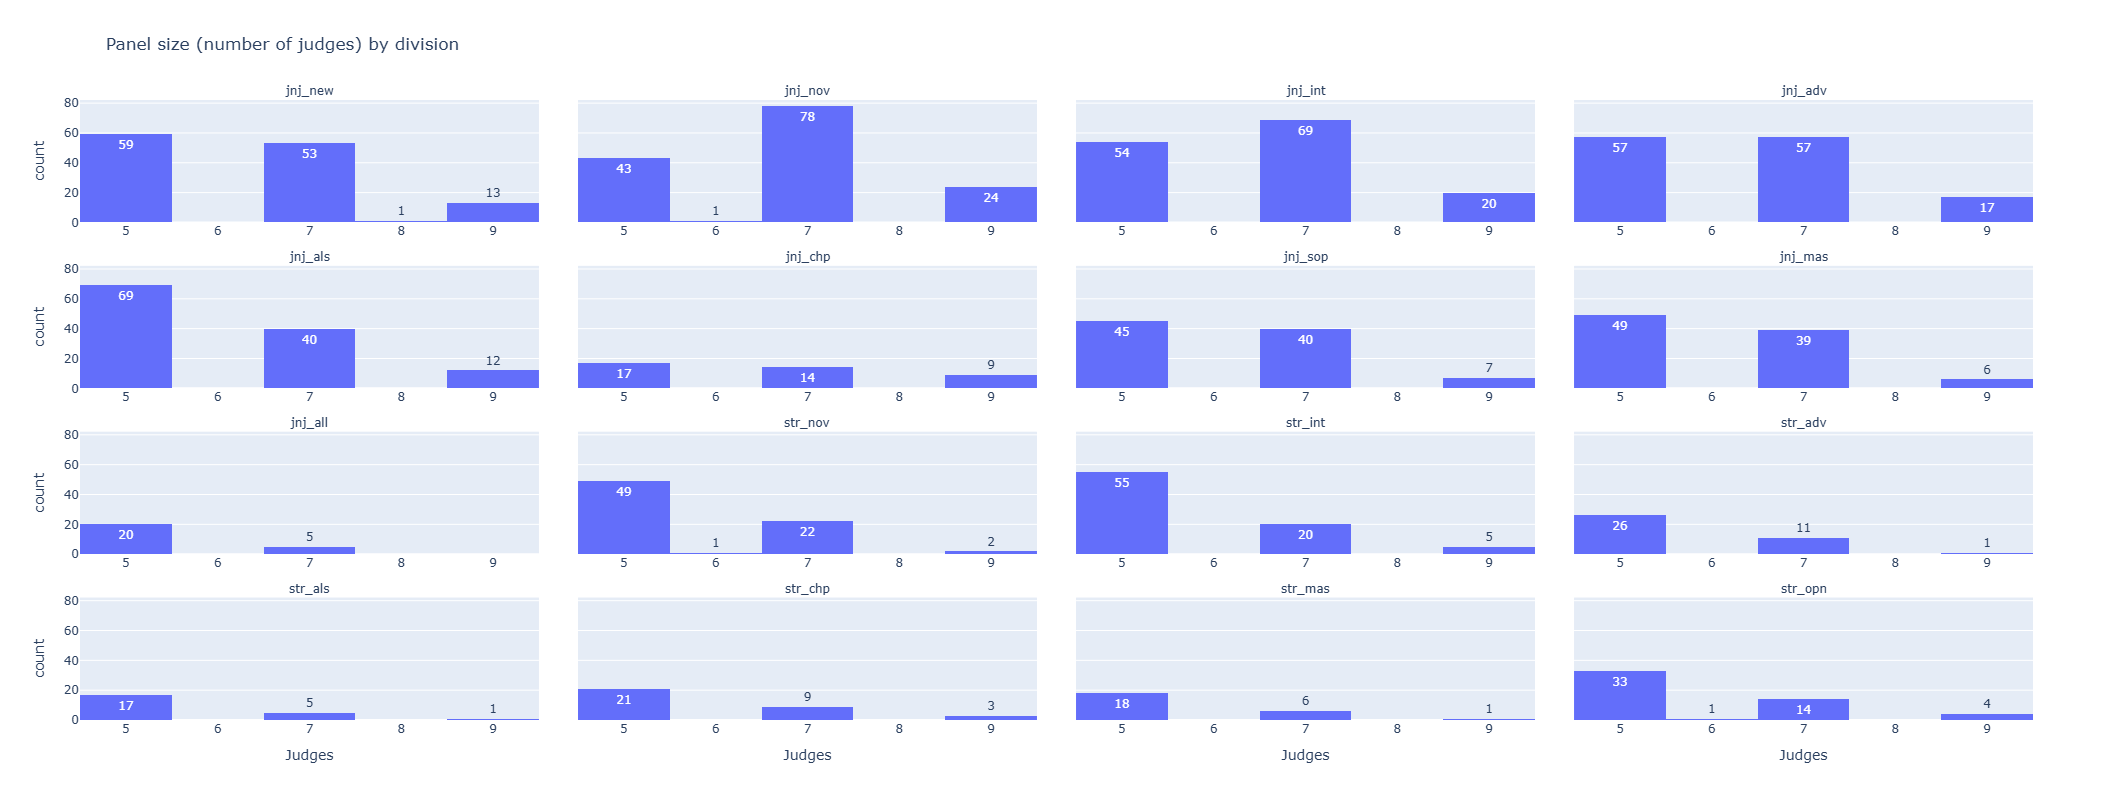

In [5]:
LEVEL_ORDER = ["new", "nov", "int", "adv", "als", "chp", "jnr", "sop", "mas", "opn", "all"]

def _div_sort_key(token):
    fmt, _, lvl = token.partition("_")
    return (fmt, LEVEL_ORDER.index(lvl) if lvl in LEVEL_ORDER else len(LEVEL_ORDER))

div_order = sorted(df["div_token"].unique(), key=_div_sort_key)

fig = px.histogram(
    df,
    x="num_judges",
    facet_col="div_token",
    facet_col_wrap=4,
    category_orders={"div_token": div_order},
    title="Panel size (number of judges) by division",
    labels={"num_judges": "Judges"},
    height=800,
    text_auto=True,
)
fig.update_layout(showlegend=False)
fig.update_xaxes(dtick=1, minallowed=4.5, maxallowed=9.5, showticklabels=True)
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig.show()

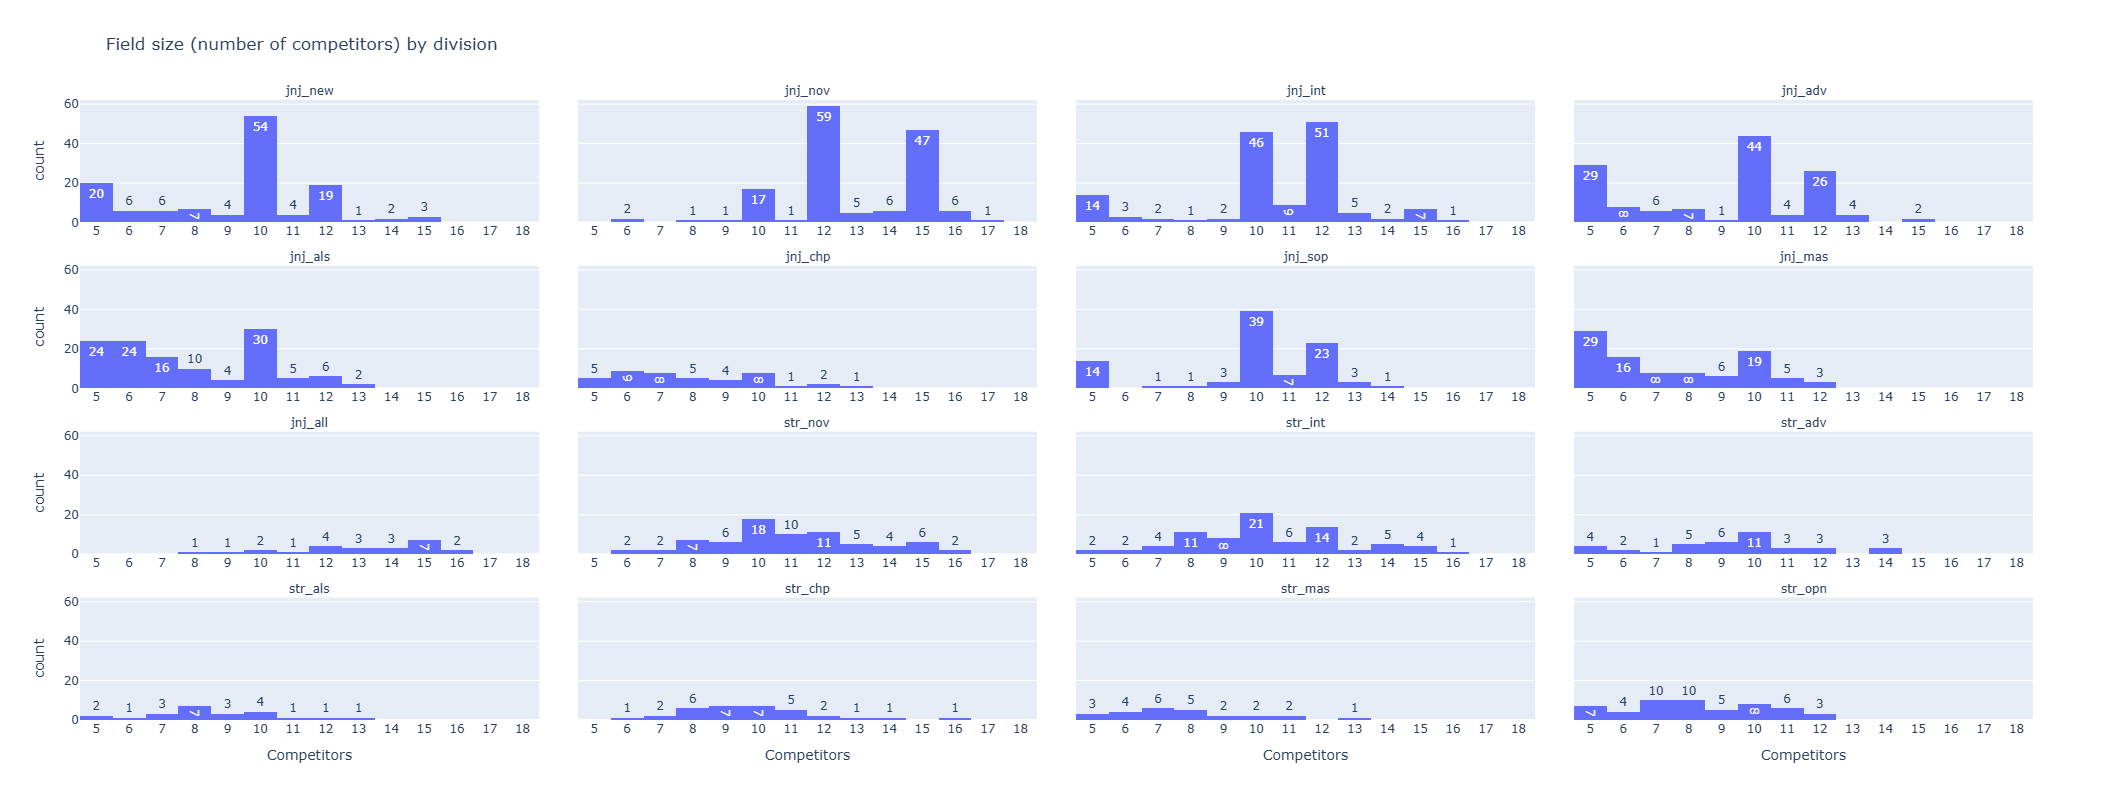

In [6]:
fig = px.histogram(
    df,
    x="num_competitors",
    facet_col="div_token",
    facet_col_wrap=4,
    category_orders={"div_token": div_order},
    title="Field size (number of competitors) by division",
    labels={"num_competitors": "Competitors"},
    height=800,
    text_auto=True,
)
fig.update_layout(showlegend=False)
fig.update_xaxes(dtick=1, maxallowed=18.5, showticklabels=True)
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig.show()